In [1]:
import sys
from pathlib import Path
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt
import math, cmath
import sys
import os
import joblib
from pathlib import Path
import pickle
import time
from mpl_toolkits.mplot3d import Axes3D
from scipy.sparse import csr_matrix, coo_matrix,  bmat, diags, identity, issparse, vstack, hstack

In [2]:
#import sys  
sys.path.insert(1,'C:\\Users\\avani\\Desktop\\Spin_Splitting_Ge_ABS')

In [3]:
import Minimal_Model_1D as M
import Minimal_model_1D_1sub as M1sub

In [4]:
hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

In [5]:
NSM = 3          # in nm
MY = 2              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0          # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 3
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

MU_const = 1 + OMEGA

ALPHAT = 20


first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919


plotting band spectrum

In [6]:
NUM = 51
KX = np.linspace(-np.pi/6,np.pi/6,NUM)
Ep = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT, DELTA, MEFF,  MU_const,  phi=PHI, px=True, kx0=KX[i])

    Hli = Fli.H_p()

    Eli, Vli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=True)
        
    #Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    Ep[i,:] = Eli

    if i%5 == 0:
        print(i)

0
5
10
15
20
25
30
35
40
45
50


In [7]:
Ep.shape

(51, 9)

In [8]:
print(Ep[0,:])

[  45.46691349   50.57373651  294.98835542  570.7856234   568.49830796  794.65240325 1068.98977826 1603.90617599 1735.02775124]


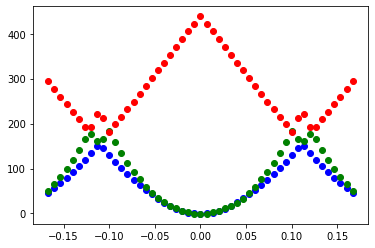

In [9]:
plt.scatter(KX/np.pi,Ep[:,0], color='blue')
plt.scatter(KX/np.pi,Ep[:,1], color = 'green')
plt.scatter(KX/np.pi,Ep[:,2], color = 'red')



In [10]:
NUM = 51
KX = np.linspace(-np.pi/6,np.pi/6,NUM)
EpM = np.empty((KX.shape[0], N))

for i in range(KX.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, px=True)
            
    Hli = Fli.HN(so = 'li', kx=KX[i])

    Eli = eigsh(Hli ,k=N,sigma=0, return_eigenvectors=False)
        
    Eli = np.sort(Eli)

    #print(Eli.shape)    
    #Eli = np.sort(Eli)
    
    EpM[i,:] = Eli

    if i%5 == 0:

        print(i)

0
5
10
15
20
25
30
35
40
45
50


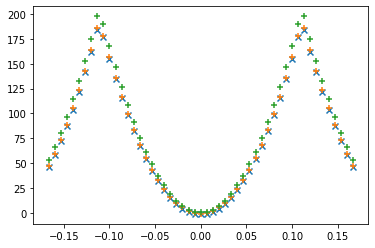

In [11]:
plt.scatter(KX/np.pi,EpM[:,0], marker='x')
plt.scatter(KX/np.pi,EpM[:,1], marker= '+')
plt.scatter(KX/np.pi,EpM[:,2], marker= '+')

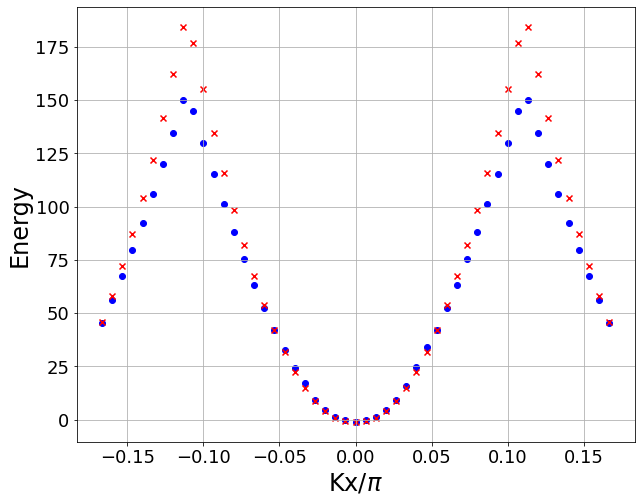

In [12]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,0], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,0], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

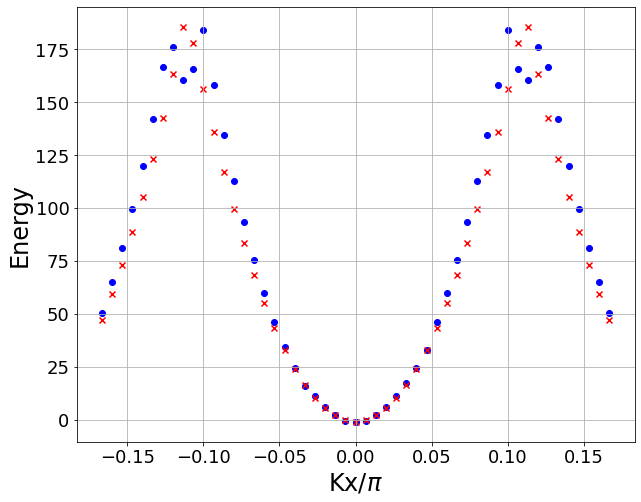

In [13]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,1], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,1], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

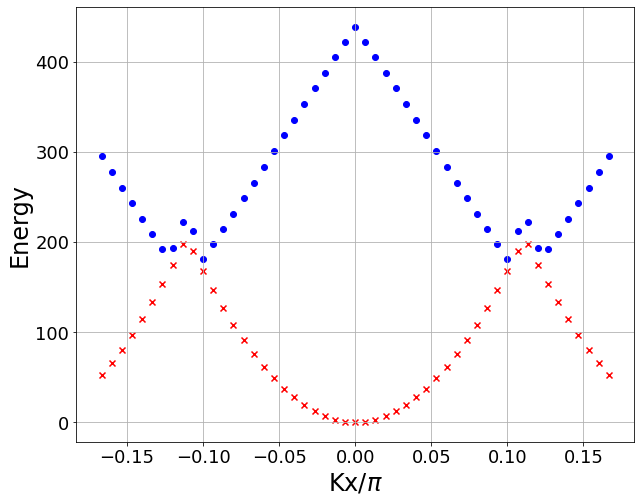

In [14]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,2], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,2], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)

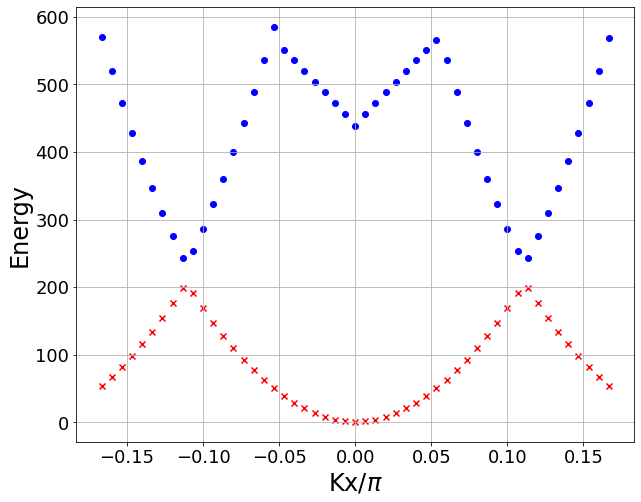

In [15]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

plt.scatter(KX/np.pi,Ep[:,3], marker='o', color='blue')
#plt.scatter(KX/np.pi,Ep[:,5], marker='1', color='blue')
#plt.scatter(KX/np.pi,Ep[:,3], marker='1', color='blue')

plt.scatter(KX/np.pi,EpM[:,3], marker='x', color='red')
#plt.scatter(KX/np.pi,EpM[:,5], marker= '+', color='red')
#plt.scatter(KX/np.pi,EpM[:,3], marker= '+', color='red')

plt.xlabel(r'Kx/$\pi$', fontsize=24)
plt.ylabel(r'Energy', fontsize=24)
plt.grid(True)
#plt.xlim(left=0)